In [5]:
'''
Exploratory Data Analysis for all Data Roles
Top 10 Locations for Data Jobs in Finland
'''

# Import Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------
# Load Data
# -----------------------------

df_fact = pd.read_csv(
    r'C:\Users\sunda\OneDrive\Desktop\Python_works\job_postings_fact.csv'
)

df_comp_dim = pd.read_csv(
    r'C:\Users\sunda\OneDrive\Desktop\Python_works\company_dim.csv'
)


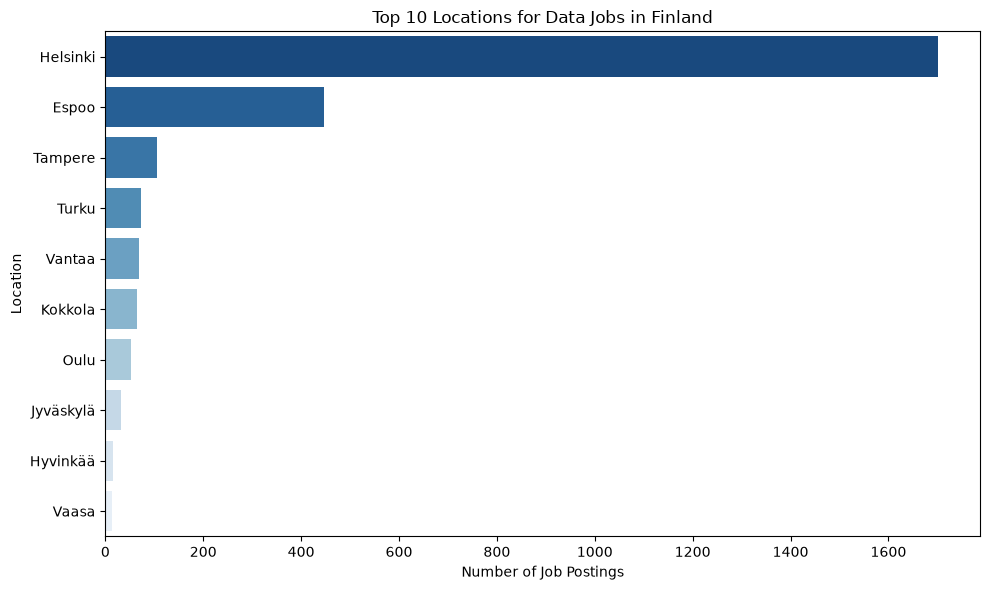

In [6]:

# -----------------------------
# Date Processing
# -----------------------------

df_fact['job_posted_date'] = pd.to_datetime(df_fact['job_posted_date'])

df_fact['year_posted'] = (
    df_fact['job_posted_date']
    .dt.year
)

# -----------------------------
# Filter Finland Data Roles
# -----------------------------

job_titles = [
    'Data Analyst',
    'Data Scientist',
    'Data Engineer',
    'Business Analyst',
    'Senior Data Analyst',
    'Senior Data Engineer',
    'Senior Data Scientist'
]

df_fin = df_fact[
    (df_fact['job_country'] == 'Finland')
    &
    (df_fact['job_title_short'].isin(job_titles))
].copy()

# -----------------------------
# Clean Location Data
# -----------------------------

# Remove 'Anywhere'
df_fin = df_fin[
    ~df_fin['job_location'].str.contains(
        'Anywhere',
        na=False
    )
]

# Remove ', Finland'
df_fin['job_location'] = (
    df_fin['job_location']
    .str.replace(', Finland', '', regex=False)
)

# Remove rows where location is only Finland
df_fin = df_fin[
    df_fin['job_location'] != 'Finland'
]

# Remove blanks just in case
df_fin = df_fin[
    df_fin['job_location'].notna()
]

# -----------------------------
# Count Locations
# -----------------------------

location_counts = (
    df_fin['job_location']
    .value_counts()
    .head(10)
    .reset_index()
)

location_counts.columns = [
    'job_location',
    'job_count'
]

# -----------------------------
# Plot
# -----------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    data=location_counts,
    x='job_count',
    y='job_location',
    palette='Blues_r',
    hue='job_location',
    legend=False
)

plt.title('Top 10 Locations for Data Jobs in Finland')
plt.xlabel('Number of Job Postings')
plt.ylabel('Location')

plt.tight_layout()
plt.show()


                     name  median_salary
13               Wärtsilä       153500.0
6                  Nortal       130886.5
4                   Nitor       121064.0
12                   Wolt       111202.0
7         Oura Health Ltd       109500.0
0                  Advian       101825.0
1                  Ageras       100500.0
8   Starship Technologies        98301.5
3                   ICEYE        88128.0
5                  Nordea        86400.0


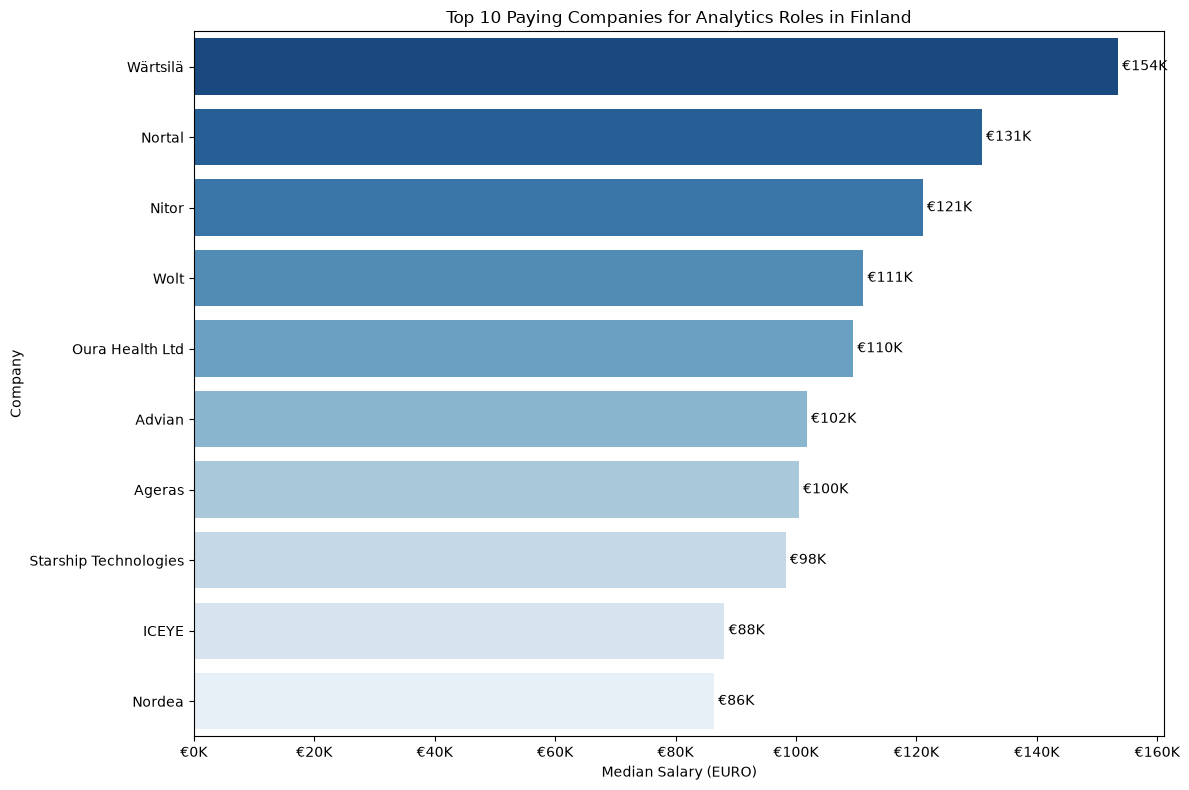

In [6]:
# EDA 1(ii) what are the companies offering this jobs in finland 
# job titles to analyze
job_titles = [
    'Data Analyst',
    'Data Scientist',
    'Data Engineer',
    'Business Analyst',
    'Senior Data Analyst',
    'Senior Data Scientist',
    'Senior Data Engineer'
]
# Remove rows with missing salaries
df_fin = df_fin.dropna(subset=['salary_year_avg'])

# Merge company names
df_fin_merged = df_fin.merge(
    df_comp_dim[['company_id', 'name']],
    on='company_id',
    how='inner'
)

# Remove companies with missing names
df_fin_merged = df_fin_merged.dropna(subset=['name'])

# Calculate median salary by company
top_companies = (
    df_fin_merged
    .groupby('name', as_index=False)
    .agg(median_salary=('salary_year_avg', 'median'))
    .sort_values('median_salary', ascending=False)
    .head(10)
)

# Print results
print(top_companies)

# Plot
plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=top_companies,
    x='median_salary',
    y='name',
    hue='name',
    palette='Blues_r',
    legend=False
)

# Add labels on bars
for container in ax.containers:
    labels = [f'€{v/1000:.0f}K' for v in container.datavalues]

    ax.bar_label(
        container,
        labels=labels,
        padding=3
    )

# Title and labels
plt.title('Top 10 Paying Companies for Analytics Roles in Finland')
plt.xlabel('Median Salary (EURO)')
plt.ylabel('Company')

# Format x-axis
formatter = FuncFormatter(lambda x, pos: f'€{x/1000:.0f}K')
ax.xaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()





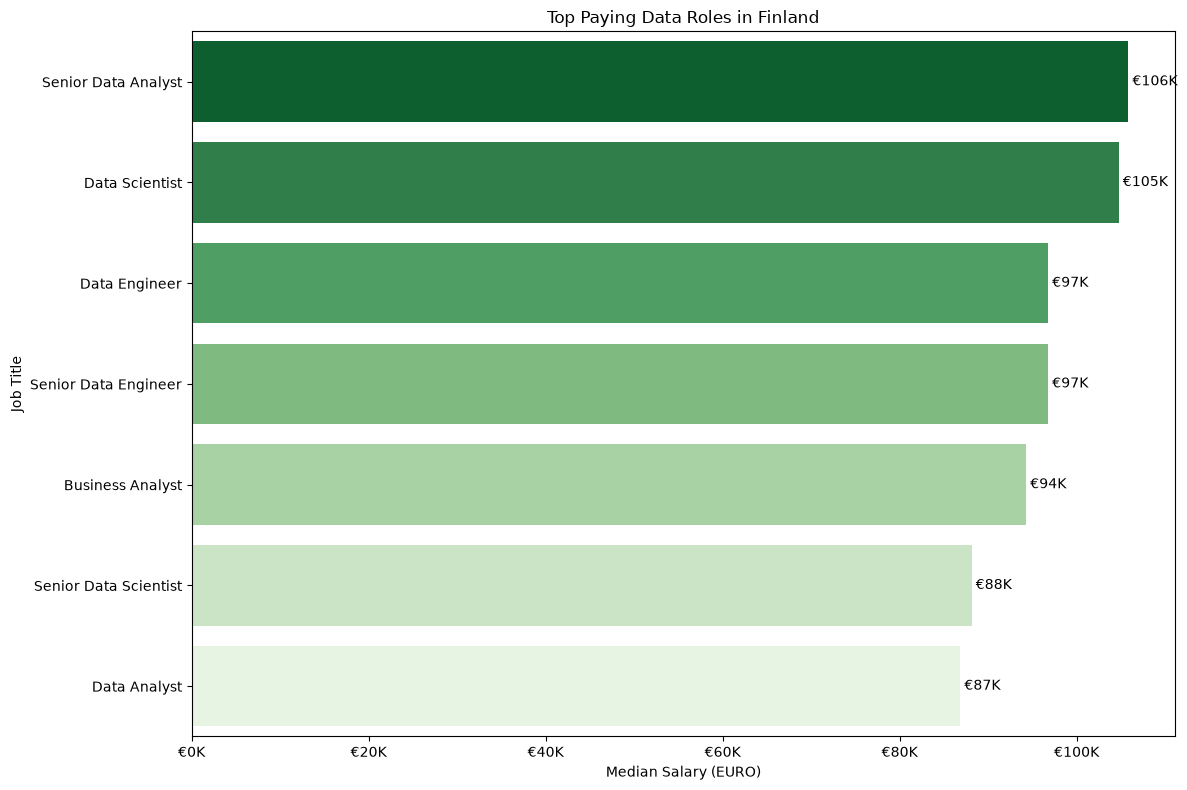

In [7]:
# EDA 1(iii) top paying jobs titles and  also top paying companies 

# what are the top job Titles and the median salary for data jobs in finland
# Job titles to analyze

job_titles = [
    'Data Analyst',
    'Data Scientist',
    'Data Engineer',
    'Business Analyst',
    'Senior Data Analyst',
    'Senior Data Scientist',
    'Senior Data Engineer'
]


# Filter Finland jobs
df_fin = df_fact[
    (df_fact['job_country'] == 'Finland') &
    (df_fact['job_title_short'].isin(job_titles))
].copy()

# get the roles salary
role_salary = (
    df_fin
    .groupby('job_title_short')['salary_year_avg']
    .median()
    .sort_values(ascending=False)
    .reset_index()
)
# plot
plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=role_salary,
    x='salary_year_avg',
    y='job_title_short',
    palette='Greens_r',
    hue='job_title_short',
    legend=False
)

# Add value labels
for container in ax.containers:
    labels = [f'€{v/1000:.0f}K' for v in container.datavalues]

    ax.bar_label(
        container,
        labels=labels,
        padding=3
    )

plt.title('Top Paying Data Roles in Finland')
plt.xlabel('Median Salary (EURO)')
plt.ylabel('Job Title')

formatter = FuncFormatter(lambda x, pos: f'€{x/1000:.0f}K')
plt.gca().xaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()

In [16]:
df_fact['year_posted'].unique()

array([2023, 2024, 2025, 2026], dtype=int32)

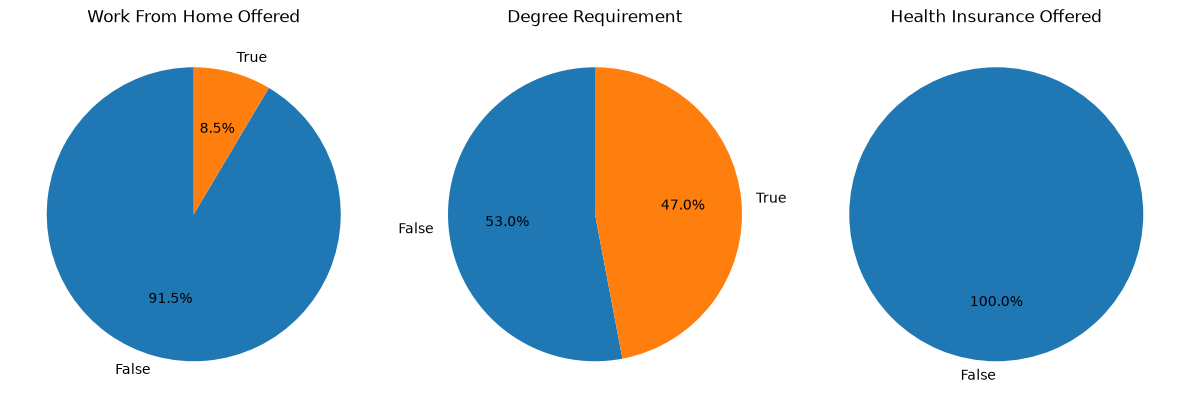

In [8]:
# EDA 2 - Benefits & Requirements Analysis

# Count True and False values
work_from_home = df_fin['job_work_from_home'].value_counts()
job_no_degree = df_fin['job_no_degree_mention'].value_counts()
job_insurance = df_fin['job_health_insurance'].value_counts()

# Create figure
fig, ax = plt.subplots(1, 3, figsize=(12, 5))

# Work From Home
plt.subplot(1, 3, 1)
plt.pie(
    work_from_home,
    labels=work_from_home.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Work From Home Offered')

# No Degree Mention
plt.subplot(1, 3, 2)
plt.pie(
    job_no_degree,
    labels=job_no_degree.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Degree Requirement')

# Health Insurance
plt.subplot(1, 3, 3)
plt.pie(
    job_insurance,
    labels=job_insurance.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Health Insurance Offered')

plt.tight_layout()
plt.show()

In [9]:
location_counts.to_csv("location_counts.csv", index=False)

top_companies.to_csv("top_companies.csv", index=False)

role_salary.to_csv("role_salary.csv", index=False)